In [13]:
import sys

import os
import re
import click
import tqdm
import pickle
import numpy as np
import torch
import PIL.Image
import dnnlib
from torch_utils import distributed as dist
from PIL import Image
from tqdm import tqdm
from matplotlib import pyplot as plt
import torch.nn.functional as F

from project_utils.paths import PROJECT_ROOT, CONFIG_DIR, DATA_DIR
from pou import gen_weight_grid, f2p, p2f

In [14]:
def edm_sampler(
    net, latents, conditions=None, class_labels=None, randn_like=torch.randn_like,
    num_steps=18, sigma_min=0.002, sigma_max=80, rho=7,
    S_churn=0, S_min=0, S_max=float('inf'), S_noise=1,
):
    # Adjust noise levels based on what's supported by the network.
    sigma_min = max(sigma_min, net.sigma_min)
    sigma_max = min(sigma_max, net.sigma_max)

    # Time step discretization.
    step_indices = torch.arange(num_steps, dtype=torch.float64, device=latents.device)
    t_steps = (sigma_max ** (1 / rho) + step_indices / (num_steps - 1) * (sigma_min ** (1 / rho) - sigma_max ** (1 / rho))) ** rho
    t_steps = torch.cat([net.round_sigma(t_steps), torch.zeros_like(t_steps[:1])]) # t_N = 0

    # Main sampling loop.
    x_next = latents.to(torch.float64) * t_steps[0]
    for i, (t_cur, t_next) in enumerate(zip(t_steps[:-1], t_steps[1:])): # 0, ..., N-1
        x_cur = x_next

        # Increase noise temporarily.
        gamma = min(S_churn / num_steps, np.sqrt(2) - 1) if S_min <= t_cur <= S_max else 0
        t_hat = net.round_sigma(t_cur + gamma * t_cur)
        x_hat = x_cur + (t_hat ** 2 - t_cur ** 2).sqrt() * S_noise * randn_like(x_cur)

        # Euler step.
        denoised = net(x_hat, t_hat, conditions, class_labels).to(torch.float64)
        d_cur = (x_hat - denoised) / t_hat
        x_next = x_hat + (t_next - t_hat) * d_cur

        # Apply 2nd order correction.
        if i < num_steps - 1:
            denoised = net(x_next, t_next, conditions, class_labels).to(torch.float64)
            d_prime = (x_next - denoised) / t_next
            x_next = x_hat + (t_next - t_hat) * (0.5 * d_cur + 0.5 * d_prime)

    return x_next




In [15]:
# device 
device=torch.device('cuda:0')


# Load network.
network_pkl = ''
network_pkl = '/home/zez0002/cond-diff-pou/outputs/00000-sqg_patch_c0-medium-gpus1-batch256-fp32/network-snapshot-002000.pkl'

print(f'Loading network from "{network_pkl}"...')
with dnnlib.util.open_url(network_pkl, verbose=True) as f:
    net_32_patch = pickle.load(f)['ema'].to(device)
    
try:
    print('condition channels: ',net_32_patch.img_cond_channels)
except:
    print('no condition channels')

Loading network from "/home/zez0002/cond-diff-pou/outputs/00000-sqg_patch_c0-medium-gpus1-batch256-fp32/network-snapshot-002000.pkl"...
condition channels:  0


torch.Size([9, 1, 32, 32])


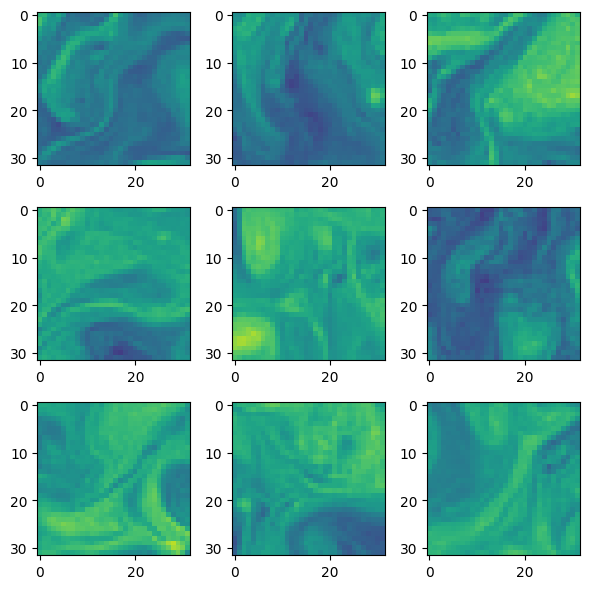

In [16]:
# generate hi res patch
batch_size = 9
latents = torch.randn([batch_size, 1, 32, 32], device=device)
samples = edm_sampler(net_32_patch, latents)
print(samples.shape)

# plot grid 
x = samples[:,0,:,:].cpu().numpy()  # convert to numpy if needed
grid_size = 3
fig, axes = plt.subplots(grid_size, grid_size, figsize=(6, 6))
# fig.tight_layout(pad=1.0)
for i in range(3):
    for j in range(3):
        axes[i, j].imshow(x[i*3 + j], cmap='viridis', vmin=-1.0, vmax=1.0)
        # axes[i, j].axis('off')
plt.tight_layout()
plt.show()

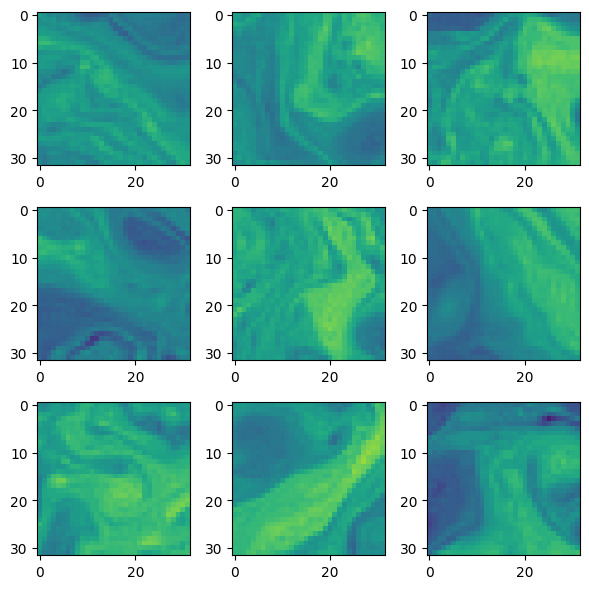

In [17]:
# load some training samples 
# show SQG orignal fields
data_snaps_dir = os.path.join(DATA_DIR, "SQG","SQG_v_0_patch_32_c_2","snaps" ) # root SQG data dir
# 
fig, axes = plt.subplots(grid_size, grid_size, figsize=(6, 6))
for i in range(3):
    for j in range(3):
        data_path = os.path.join(data_snaps_dir, f"sample_{i*3 + j:06d}.pt")
        data = torch.load(data_path)
        x = data['targets']
        axes[i, j].imshow(x[0], cmap='viridis', vmin=-1.0, vmax=1.0)
        # axes[i, j].axis('off')
plt.tight_layout()
plt.show()

In [18]:
def edm_sampler_pou(
    weight_grid_2d, net, latents, conditions=None, 
    class_labels=None, randn_like=torch.randn_like,
    num_steps=18, sigma_min=0.002, sigma_max=80, rho=7,
    S_churn=0, S_min=0, S_max=float('inf'), S_noise=1,
):
    # Adjust noise levels based on what's supported by the network.
    sigma_min = max(sigma_min, net.sigma_min)
    sigma_max = min(sigma_max, net.sigma_max)

    # Time step discretization.
    step_indices = torch.arange(num_steps, dtype=torch.float64, device=latents.device)
    t_steps = (sigma_max ** (1 / rho) + step_indices / (num_steps - 1) * (sigma_min ** (1 / rho) - sigma_max ** (1 / rho))) ** rho
    t_steps = torch.cat([net.round_sigma(t_steps), torch.zeros_like(t_steps[:1])]) # t_N = 0

    # condition (BCHW)
    patch_cond = f2p(conditions) if conditions is not None else None
    weight_grid_flat = weight_grid_2d.view(-1, 1, weight_grid_2d.shape[2], weight_grid_2d.shape[3]).to(latents.device)

    # Main sampling loop.
    x_next = latents.to(torch.float64) * t_steps[0]
    for i, (t_cur, t_next) in enumerate(zip(t_steps[:-1], t_steps[1:])): # 0, ..., N-1
        x_cur = x_next

        # Increase noise temporarily.
        gamma = min(S_churn / num_steps, np.sqrt(2) - 1) if S_min <= t_cur <= S_max else 0
        t_hat = net.round_sigma(t_cur + gamma * t_cur)
        x_hat = x_cur + (t_hat ** 2 - t_cur ** 2).sqrt() * S_noise * randn_like(x_cur)

        # Euler step.
        # x_hat (B, C, H, W)  (B, C, 128, 128)
        patch_x_hat = f2p(x_hat) # patch_x_hat: (B*n_patch*n_patch, C, patch_size, patch_size)
        # patch_x_hat: (B*7*7, C, 32, 32)
        patch_denoised = net(patch_x_hat, t_hat, patch_cond, class_labels).to(torch.float64) 
        denoised = p2f(patch_denoised, weight_grid_flat) # apply PoU to get denoised full image
        ##################
        # plt.figure(figsize=(6,6))
        # plt.imshow(denoised[0,0,:,:].cpu().numpy(), cmap='viridis', vmin=-1.0, vmax=1.0)
        # plt.title(f'sigma: {t_hat.item():.4f}')
        # plt.show()
        ##################
        d_cur = (x_hat - denoised) / t_hat
        x_next = x_hat + (t_next - t_hat) * d_cur

        # Apply 2nd order correction.
        if i < num_steps - 1:
            # denoised = net(x_next, t_next, conditions, class_labels).to(torch.float64)
            
            patch_x_next = f2p(x_next)
            patch_denoised = net(patch_x_next, t_next, patch_cond, class_labels).to(torch.float64) 
            denoised = p2f(patch_denoised, weight_grid_flat)


            d_prime = (x_next - denoised) / t_next
            x_next = x_hat + (t_next - t_hat) * (0.5 * d_cur + 0.5 * d_prime)

    return x_next

torch.Size([15, 15, 32, 32])
torch.Size([1, 1, 256, 256])


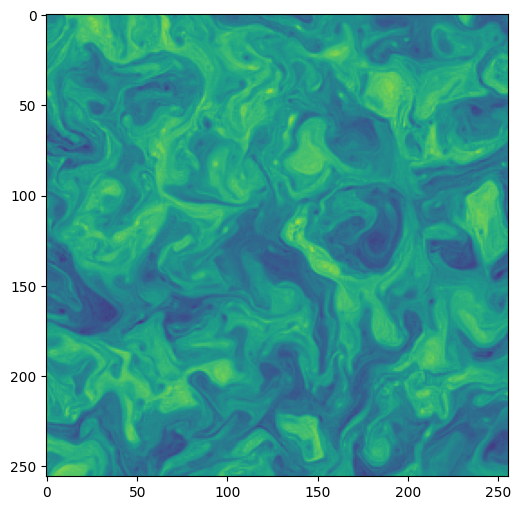

In [32]:

patch_size = 32
expand_ratio = 8
batch_size = 1

weight_grid_2d = gen_weight_grid(patch_size, expand_ratio)
print(weight_grid_2d.shape)

# PoU generation
output_size = patch_size * expand_ratio
latents = torch.randn([batch_size, 1, output_size, output_size], device=device)
samples = edm_sampler_pou(weight_grid_2d, net_32_patch, latents, num_steps=18)
print(samples.shape)

plt.figure(figsize=(6,6))
plt.imshow(samples[0,0,:,:].cpu().numpy(), cmap='viridis', vmin=-1.0, vmax=1.0)
# plt.axis('off')
plt.show()

loaded raw fields:  torch.Size([1001, 2, 128, 128])


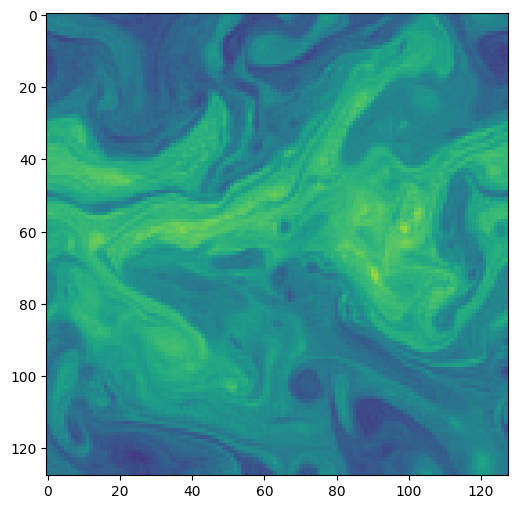

In [31]:
# show SQG orignal fields
dataset_dir = os.path.join(DATA_DIR, "SQG") # root SQG data dir
fields_all = torch.load(os.path.join(dataset_dir, 'SQG_fields.pt'))
print('loaded raw fields: ', fields_all.shape)

# plot 
snap_id = 3
plt.figure(figsize=(6,6))
plt.imshow(fields_all[snap_id,0,:,:].cpu().numpy(), cmap='viridis', vmin=-1.0, vmax=1.0)
# plt.axis('off')
plt.show()